# Data audit and first baseline (Home Credit Default Risk)

The aim of this project is to predict which applicants may experience payment difficulties when applying for a loan. Using applicant information, such as income, credit amount, age, education, and family situation, models estimate the likelihood of payment difficulties.

This is important for lenders because better predictions can support credit-risk assessment and help them make more informed lending decisions. However, credit decisions should not rely on prediction accuracy alone. Understanding why a model makes a prediction, and whether its errors differ across applicant groups, is also important for transparency and fairness.


#### Purpose

This notebook focuses on initial data exploration, data-quality checks and baseline modelling. It represents an early stage of the project rather than the final machine-learning pipeline.

- This is an **early-stage notebook** covering data auditing and initial baseline modelling. It uses `application_train.csv`, 16 candidate features and a single stratified 80:20 train-test split.
- It is **not the final modelling pipeline**. Random Forest, XGBoost, five-fold cross-validation, SHAP explainability, full fairness analysis, probability calibration, MLflow tracking and automated tests are covered in the later project pipeline.
- The raw dataset is **not included** in this repository. Download it from Kaggle and configure the local data directory as explained in the Data section.

#### Scope

The results in this notebook are exploratory and should not be presented as the final model results or final fairness findings. The final thesis analysis is conducted using the main project pipeline. Later stages will compare models, examine their explanations using SHAP, and investigate fairness across applicant groups.

Refrences Dataset: Home Credit (2018), *Home Credit Default Risk*, Kaggle: https://www.kaggle.com/competitions/home-credit-default-risk/data


## 1. Importing libraries and setting the Data Path

- This section imports the required Python libraries and configures the location of the Home Credit dataset.

- Set the `HOME_CREDIT_DATA_DIR` environment variable to the folder containing `application_train.csv` and `HomeCredit_columns_description.csv`.

- Uses the default location `~/Desktop/home_credit_default_risk`.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score, brier_score_loss, precision_score, recall_score, f1_score
)

DATA_DIR = Path(os.environ.get(
    "HOME_CREDIT_DATA_DIR",
    Path.home() / "Desktop" / "home_credit_default_risk",
))
RANDOM_STATE = 42


## 2. Load and validate the dataset

In [2]:
df = pd.read_csv(DATA_DIR / "application_train.csv")
n_rows, n_cols = df.shape
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Data Exploration

These basic exploratory steps included:

- Shape
- Datatypes
- Describes
- Target variable Distribution
- Payment-difficulty rate
- Duplicate Rows
- Baseline scores
- Missing values


### 3a. Column Names and Data Types
I did a basic exploration of the datatypes and some basic statistics of the dataset

In [3]:
print('Shape:', df.shape)
df.dtypes

Shape: (307511, 122)


SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE             object
CODE_GENDER                    object
FLAG_OWN_CAR                   object
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

### 3b. Basic statistics and numerical-value investigation
The .describe() function provides descriptive statistics of all the numeric columns in the dataset. This is very helpful in terms of count, mean, min, and max values.

And doing some additional checks below focus on selected financial and applicant variables where unusually large or rare values may affect data understanding and preprocessing. Also, an extreme value is not automatically an error. The purpose is to identify and investigate unusual observations, not to remove them solely because they are rare

In [4]:
df.describe().T.round(2)
df["AMT_INCOME_TOTAL"].nlargest(10)

12840     117000000.0
203693     18000090.0
246858     13500000.0
77768       9000000.0
131127      6750000.0
103006      4500000.0
187833      4500000.0
204564      4500000.0
287463      4500000.0
181698      3950059.5
Name: AMT_INCOME_TOTAL, dtype: float64

In [5]:
# Applicants' income
df.loc[
    df["AMT_INCOME_TOTAL"].nlargest(10).index,
    ["SK_ID_CURR", "TARGET", "AMT_INCOME_TOTAL",
     "AMT_CREDIT", "AMT_ANNUITY", "NAME_INCOME_TYPE"]
]

,SK_ID_CURR,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NAME_INCOME_TYPE
12840,114967,1,117000000.0,562491.0,26194.5,Working
203693,336147,0,18000090.0,675000.0,69295.5,Commercial associate
246858,385674,0,13500000.0,1400503.5,130945.5,Commercial associate
77768,190160,0,9000000.0,1431531.0,132601.5,Working
131127,252084,0,6750000.0,790830.0,52978.5,Working
103006,219563,0,4500000.0,2250000.0,225000.0,Working
187833,317748,0,4500000.0,835380.0,42651.0,Working
204564,337151,0,4500000.0,450000.0,47749.5,Working
287463,432980,0,4500000.0,1755000.0,61132.5,Working
181698,310601,0,3950059.5,675000.0,66217.5,Commercial associate


- Identifies the ten applicants with the highest annual income and examines their payment-difficulty status, credit amounts, annual repayment obligations and income types. It helps identify unusually high income values and explore their relationship with other financial variables.

In [6]:
# checking the income distribution
df["AMT_INCOME_TOTAL"].quantile([0.90, 0.95, 0.99, 0.995, 0.999])

0.900    270000.0
0.950    337500.0
0.990    472500.0
0.995    630000.0
0.999    900000.0
Name: AMT_INCOME_TOTAL, dtype: float64

- The income distribution is right-skewed, with the 99th percentile at 472,500 and the 99.9th percentile at 900,000. This indicates that a small proportion of applicants have substantially higher incomes than the majority.

In [7]:
# calculate the number of extreme observation
income_threshold = df["AMT_INCOME_TOTAL"].quantile(0.99)
print("99th percentile threshold:", income_threshold)
print("Records above threshold:", (df["AMT_INCOME_TOTAL"] > income_threshold).sum())
print("Percentage of applications:", 
      round((df["AMT_INCOME_TOTAL"] > income_threshold).mean() * 100, 2), "%")

99th percentile threshold: 472500.0
Records above threshold: 3014
Percentage of applications: 0.98 %


In [8]:
# AMOUNT INCOME_TOTAL
df["AMT_CREDIT"].quantile([0.90, 0.95, 0.99, 0.995, 0.999])

0.900    1133748.0
0.950    1350000.0
0.990    1854000.0
0.995    2022565.5
0.999    2517300.0
Name: AMT_CREDIT, dtype: float64

In [9]:
# AMT_ANNUITY
df["AMT_ANNUITY"].quantile([0.90, 0.95, 0.99, 0.995, 0.999])

0.900     45954.0
0.950     53325.0
0.990     70006.5
0.995     79758.0
0.999    110047.5
Name: AMT_ANNUITY, dtype: float64

- This is another important financial variable because it represents the loan repayment amount.

In [10]:
df["AMT_ANNUITY"].describe()

count    307499.000000
mean      27108.573909
std       14493.737315
min        1615.500000
25%       16524.000000
50%       24903.000000
75%       34596.000000
max      258025.500000
Name: AMT_ANNUITY, dtype: float64

In [11]:
# CNT_CHILDREN - Outlier investigation
df["CNT_CHILDREN"].value_counts().sort_index().tail(15)

CNT_CHILDREN
0     215371
1      61119
2      26749
3       3717
4        429
5         84
6         21
7          7
8          2
9          2
10         2
11         1
12         2
14         3
19         2
Name: count, dtype: int64

- The number of children is highly concentrated between 0 and 2. Only two applicants reported 19 children, while three reported 14. Although these are rare observations, they are not necessarily data errors. Therefore, no records were removed or modified.

In [12]:
# check AMT_REQ_CREDIT_BUREAU_QRT
df["AMT_REQ_CREDIT_BUREAU_QRT"].value_counts().sort_index().tail(15)

AMT_REQ_CREDIT_BUREAU_QRT
0.0      215417
1.0       33862
2.0       14412
3.0        1717
4.0         476
5.0          64
6.0          28
7.0           7
8.0           7
19.0          1
261.0         1
Name: count, dtype: int64

- Most applicants reported zero to two quarterly credit bureau enquiries. Higher values were increasingly rare, with one applicant recording 19 enquiries and another recording 261

In [13]:
# Investigate unusually high credit bureau enquiry values

df.loc[
    df["AMT_REQ_CREDIT_BUREAU_QRT"].isin([19, 261]),
    [
        "SK_ID_CURR",
        "AMT_REQ_CREDIT_BUREAU_HOUR",
        "AMT_REQ_CREDIT_BUREAU_DAY",
        "AMT_REQ_CREDIT_BUREAU_WEEK",
        "AMT_REQ_CREDIT_BUREAU_MON",
        "AMT_REQ_CREDIT_BUREAU_QRT",
        "AMT_REQ_CREDIT_BUREAU_YEAR",
        "TARGET"
    ]
]

,SK_ID_CURR,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
239474,377322,0.0,0.0,0.0,1.0,261.0,0.0,0
253541,393383,0.0,0.0,0.0,0.0,19.0,2.0,1


- The two unusual observations were investigated using other credit bureau enquiry variables. The applicant with 261 quarterly enquiries reported no enquiries in the other periods, suggesting a possible data-quality issue. The applicant with 19 quarterly enquiries also reported two annual enquiries and had a payment-difficulty indicator of 1.

In [14]:
# Load the original Home Credit column descriptions

description_path = DATA_DIR / "HomeCredit_columns_description.csv"

column_descriptions = pd.read_csv(
    description_path,
    encoding="latin1"
)

print("Shape:", column_descriptions.shape)
display(column_descriptions.head())

Shape: (219, 5)


,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN


- The original Home Credit column-description file was loaded to understand the meaning of the dataset variables. It contains 219 entries and provides descriptions of the columns, their corresponding tables and any special values, supporting accurate data interpretation during the analysis.

In [15]:
# Find credit bureau enquiry variable definitions

bureau_descriptions = column_descriptions[
    column_descriptions["Row"].str.contains(
        "AMT_REQ_CREDIT_BUREAU",
        case=False,
        na=False
    )
]

display(
    bureau_descriptions[
        ["Table", "Row", "Description", "Special"]
    ].to_string(index=False)
)

'                       Table                        Row                                                                                                                Description Special\napplication_{train|test}.csv AMT_REQ_CREDIT_BUREAU_HOUR                                          Number of enquiries to Credit Bureau about the client one hour before application     NaN\napplication_{train|test}.csv  AMT_REQ_CREDIT_BUREAU_DAY   Number of enquiries to Credit Bureau about the client one day before application (excluding one hour before application)     NaN\napplication_{train|test}.csv AMT_REQ_CREDIT_BUREAU_WEEK   Number of enquiries to Credit Bureau about the client one week before application (excluding one day before application)     NaN\napplication_{train|test}.csv  AMT_REQ_CREDIT_BUREAU_MON Number of enquiries to Credit Bureau about the client one month before application (excluding one week before application)     NaN\napplication_{train|test}.csv  AMT_REQ_CREDIT_BUREAU_QRT  Nu

- The official Home Credit documentation was used to identify the meaning of the credit bureau enquiry variables. These variables record enquiries over different periods before the loan application, from one hour to one year. This information helps interpret unusual values, particularly the extreme quarterly enquiry count identified earlier.

In [16]:
# Verify the two unusual quarterly enquiry records

df.loc[
    df["AMT_REQ_CREDIT_BUREAU_QRT"].isin([19, 261]),
    [
        "SK_ID_CURR",
        "AMT_REQ_CREDIT_BUREAU_QRT",
        "TARGET"
    ]
].to_string(index=False)

' SK_ID_CURR  AMT_REQ_CREDIT_BUREAU_QRT  TARGET\n     377322                      261.0       0\n     393383                       19.0       1'

- The verification confirmed two unusual quarterly credit bureau enquiry records: applicant 377322 reported 261 enquiries and had TARGET = 0, while applicant 393383 reported 19 enquiries and had TARGET = 1. These observations were retained for further assessment, as their unusual values alone do not confirm data errors.

### 3c. Categorical Variable Quality Checks

- Categorical variables are inspected for their available values, missing entries, special labels and category frequencies. This helps identify data-quality issues that may need to be handled during preprocessing.

In [17]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns)

Number of categorical columns: 16

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


- The dataset contains 16 categorical columns, covering applicant characteristics, income types, housing conditions and application-related information.

#### 3C.1 Examination of Unique Categorical Values

The unique values in each categorical variable were examined to identify the different categories present in the dataset and detect any unexpected entries.

In [18]:
# Examine unique values in categorical variables

for column in categorical_columns:
    print(f"\n{column}")
    print("Number of unique values:", df[column].nunique(dropna=False))
    print("Unique values:", df[column].unique())


NAME_CONTRACT_TYPE
Number of unique values: 2
Unique values: ['Cash loans' 'Revolving loans']

CODE_GENDER
Number of unique values: 3
Unique values: ['M' 'F' 'XNA']

FLAG_OWN_CAR
Number of unique values: 2
Unique values: ['N' 'Y']

FLAG_OWN_REALTY
Number of unique values: 2
Unique values: ['Y' 'N']

NAME_TYPE_SUITE
Number of unique values: 8
Unique values: ['Unaccompanied' 'Family' 'Spouse, partner' 'Children' 'Other_A' nan
 'Other_B' 'Group of people']

NAME_INCOME_TYPE
Number of unique values: 8
Unique values: ['Working' 'State servant' 'Commercial associate' 'Pensioner' 'Unemployed'
 'Student' 'Businessman' 'Maternity leave']

NAME_EDUCATION_TYPE
Number of unique values: 5
Unique values: ['Secondary / secondary special' 'Higher education' 'Incomplete higher'
 'Lower secondary' 'Academic degree']

NAME_FAMILY_STATUS
Number of unique values: 6
Unique values: ['Single / not married' 'Married' 'Civil marriage' 'Widow' 'Separated'
 'Unknown']

NAME_HOUSING_TYPE
Number of unique values: 

- CODE_GENDER contains M, F and XNA.
- NAME_TYPE_SUITE contains missing values (NaN).
- EMERGENCYSTATE_MODE contains Yes, No and missing values.
- Other variables also need to be checked because the output is truncated.
- XNA and NaN are not necessarily the same thing. We should investigate them separately rather than automatically treating them as errors

#### 3C.2 Missing Values in Categorical Variables

This check examines missing values in categorical variables to identify which columns contain incomplete information and how many records are affected.

In [19]:
categorical_missing = df[categorical_columns].isnull().sum()

categorical_missing = categorical_missing[
    categorical_missing > 0
].sort_values(ascending=False)

print("Categorical columns with missing values:")
display(categorical_missing.to_frame(name="Missing Count"))

Categorical columns with missing values:


,Missing Count
FONDKAPREMONT_MODE,210295
WALLSMATERIAL_MODE,156341
HOUSETYPE_MODE,154297
EMERGENCYSTATE_MODE,145755
OCCUPATION_TYPE,96391
NAME_TYPE_SUITE,1292


- 6 categorical variables contain missing values. Missingness is particularly high in property-related variables. All application records were retained, and no missing values were modified during this initial check.

#### 3C.3 Investigation of Unusual Categorical Values

- Have checked categorical variables for special or unexpected labels such as "XNA" and "Unknown". Their frequencies were counted to identify categories that may represent missing or unspecified information

In [20]:
for column in categorical_columns:
    special_values = df[column].astype("string").str.upper().isin(
        ["XNA", "UNKNOWN", "OTHER"]
    )

    if special_values.any():
        print(f"\n{column}")
        print(df.loc[special_values, column].value_counts())


CODE_GENDER
CODE_GENDER
XNA    4
Name: count, dtype: int64

NAME_FAMILY_STATUS
NAME_FAMILY_STATUS
Unknown    2
Name: count, dtype: int64

ORGANIZATION_TYPE
ORGANIZATION_TYPE
XNA      55374
Other    16683
Name: count, dtype: int64


- Special categorical labels were identified in CODE_GENDER, NAME_FAMILY_STATUS and ORGANIZATION_TYPE. The highest frequency was observed for XNA in ORGANIZATION_TYPE, with 55,374 records.

#### 3C.4 Categorical Value Frequency Analysis

- Need to check the frequency of each category to identify rare or uncommon values within the categorical variables.

In [21]:
# Examine category frequencies

for column in categorical_columns:
    print(f"\n--- {column} ---")
    display(df[column].value_counts(dropna=False))


--- NAME_CONTRACT_TYPE ---


NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64


--- CODE_GENDER ---


CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64


--- FLAG_OWN_CAR ---


FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

... (22 outputs left out)


--- WALLSMATERIAL_MODE ---


WALLSMATERIAL_MODE
NaN             156341
Panel            66040
Stone, brick     64815
Block             9253
Wooden            5362
Mixed             2296
Monolithic        1779
Others            1625
Name: count, dtype: int64


--- EMERGENCYSTATE_MODE ---


EMERGENCYSTATE_MODE
No     159428
NaN    145755
Yes      2328
Name: count, dtype: int64

- The frequency distributions of all 16 categorical variables were examined to identify common, rare and special category values, as well as missing entries. The results provide an overview of category distributions and help identify potential data-quality issues relevant to preprocessing.

- All categories and records were retained during this initial assessment. No category merging, removal or modification was performed at this stage.


#### 3C.5 Verification of Categorical Values Against Original Documentation

The original documentation provides descriptions for the categorical variables and identifies certain special or normalized values. Some variables appear more than once in the documentation because they are referenced in different dataset tables. This documentation was used to support the interpretation of categorical variables before preprocessing.


In [22]:
categorical_documentation = column_descriptions[
    column_descriptions["Row"].astype(str).str.strip().isin(categorical_columns)
][["Row", "Description", "Special"]].drop_duplicates()

display(categorical_documentation.sort_values("Row"))


,Row,Description,Special
3,CODE_GENDER,Gender of the client,NaN
90,EMERGENCYSTATE_MODE,Normalized information about building where th...,normalized
4,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
86,FONDKAPREMONT_MODE,Normalized information about building where th...,normalized
87,HOUSETYPE_MODE,Normalized information about building where th...,normalized
2,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
175,NAME_CONTRACT_TYPE,"Contract product type (Cash loan, consumer loa...",NaN
13,NAME_EDUCATION_TYPE,Level of highest education the client achieved,NaN
14,NAME_FAMILY_STATUS,Family status of the client,NaN


In [23]:
application_documentation = column_descriptions[
    (
        column_descriptions["Table"].astype(str).str.strip()
        == "application_{train|test}.csv"
    )
    &
    (
        column_descriptions["Row"].astype(str).str.strip()
        .isin(categorical_columns)
    )
][["Row", "Description", "Special"]].drop_duplicates(subset=["Row"])

display(application_documentation.sort_values("Row"))



,Row,Description,Special
3,CODE_GENDER,Gender of the client,NaN
90,EMERGENCYSTATE_MODE,Normalized information about building where th...,normalized
4,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
86,FONDKAPREMONT_MODE,Normalized information about building where th...,normalized
87,HOUSETYPE_MODE,Normalized information about building where th...,normalized
2,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
13,NAME_EDUCATION_TYPE,Level of highest education the client achieved,NaN
14,NAME_FAMILY_STATUS,Family status of the client,NaN
15,NAME_HOUSING_TYPE,What is the housing situation of the client (r...,NaN


- It was filtered to include only entries related to the application training and test datasets, excluding duplicate references from other tables.

The original Home Credit documentation was used to verify the 16 categorical variables in the application dataset. All 16 variables were successfully matched with their corresponding documentation entries.

The documentation describes applicant characteristics, financial and employment information, housing conditions and application details. Four building-related variables (EMERGENCYSTATE_MODE, FONDKAPREMONT_MODE, HOUSETYPE_MODE and WALLSMATERIAL_MODE) are marked as normalized information.

All 16 categorical variables were retained. No variables or records were removed or modified as a result of this verification.


### 3C.6 Investigation of special and potentially inconsistent categorical values

The special labels identified earlier were reviewed:

- `CODE_GENDER`: XNA
- `NAME_FAMILY_STATUS`: Unknown
- `ORGANIZATION_TYPE`: XNA and Other

The aim wass to distinguish valid documented categories from missing, unspecified or potentially anomalous values.


In [24]:
special_category_checks = {
    "CODE_GENDER": ["XNA"],
    "NAME_FAMILY_STATUS": ["Unknown"],
    "ORGANIZATION_TYPE": ["XNA", "Other"]
}

for column, special_values in special_category_checks.items():
    print(f"\n--- {column} ---")
    print(
        df[column]
        .value_counts(dropna=False)
        .reindex(special_values, fill_value=0)
    )



--- CODE_GENDER ---
CODE_GENDER
XNA    4
Name: count, dtype: int64

--- NAME_FAMILY_STATUS ---
NAME_FAMILY_STATUS
Unknown    2
Name: count, dtype: int64

--- ORGANIZATION_TYPE ---
ORGANIZATION_TYPE
XNA      55374
Other    16683
Name: count, dtype: int64


- CODE_GENDER = XNA: only 4 records; likely an unspecified gender value.
- NAME_FAMILY_STATUS = Unknown: 2 records; explicitly unspecified.
- ORGANIZATION_TYPE = XNA: 55,374 records; requires careful treatment as an unspecified organization type.
- ORGANIZATION_TYPE = Other: 16,683 records; a separate category, not automatically an error.

#### 3C.6.1 Retrieve original documentation for the three categorical variables

In [25]:
special_value_documentation = column_descriptions[
    (
        column_descriptions["Table"].astype(str).str.strip()
        == "application_{train|test}.csv"
    )
    &
    (
        column_descriptions["Row"].astype(str).str.strip().isin(
            ["CODE_GENDER", "NAME_FAMILY_STATUS", "ORGANIZATION_TYPE"]
        )
    )
][["Row", "Description", "Special"]].drop_duplicates()

display(special_value_documentation.sort_values("Row"))


,Row,Description,Special
3,CODE_GENDER,Gender of the client,NaN
14,NAME_FAMILY_STATUS,Family status of the client,NaN
40,ORGANIZATION_TYPE,Type of organization where client works,NaN


- The original Home Credit documentation confirms the meanings of all three variables but does not explain the special labels XNA, Unknown or Other. Therefore, these labels cannot be assumed to be officially defined categories or data errors based on the documentation alone.

#### 3C.6.2 Investigation of XNA and DAYS_EMPLOYED Placeholder Values

In [26]:
pd.crosstab(
    df["ORGANIZATION_TYPE"] == "XNA",
    df["DAYS_EMPLOYED"] == 365243,
    rownames=["ORGANIZATION_TYPE is XNA"],
    colnames=["DAYS_EMPLOYED is 365243"]
)


DAYS_EMPLOYED is 365243,False,True
ORGANIZATION_TYPE is XNA,,
False,252137,0
True,0,55374



- The investigation identified special labels in three categorical variables: `CODE_GENDER`, `NAME_FAMILY_STATUS` and `ORGANIZATION_TYPE`.
- The `XNA` category appeared four times in `CODE_GENDER`, while `Unknown` appeared twice in `NAME_FAMILY_STATUS`. In `ORGANIZATION_TYPE`, `XNA` appeared in 55,374 records and `Other` appeared in 16,683 records.
- A cross-tabulation was conducted to investigate the relationship between `ORGANIZATION_TYPE = XNA` and the special placeholder value `DAYS_EMPLOYED = 365243`. The results showed an exact correspondence: all 55,374 records with `ORGANIZATION_TYPE = XNA` also contained the `DAYS_EMPLOYED` placeholder, and no records outside this group contained that placeholder.
- This finding indicates a strong relationship between the two variables and suggests that they represent a shared employment-information condition in the dataset.

The special labels and placeholder values were retained during the initial data-quality assessment. No records were removed or categories changed.


#### 3C.6.3 Calculate percentages for selected categorical findings

In [27]:
total_records = len(df)

findings = {
    "CODE_GENDER - XNA": 4,
    "NAME_FAMILY_STATUS - Unknown": 2,
    "NAME_TYPE_SUITE - Missing": 1292,
    "OCCUPATION_TYPE - Missing": 96391,
    "ORGANIZATION_TYPE - XNA": 55374,
    "FONDKAPREMONT_MODE - Missing": 210295
}

percentage_table = pd.DataFrame({
    "Finding": findings.keys(),
    "Frequency": findings.values()
})

percentage_table["Percentage"] = (
    percentage_table["Frequency"] / total_records * 100
).round(2)

display(percentage_table)

,Finding,Frequency,Percentage
0,CODE_GENDER - XNA,4,0.00
1,NAME_FAMILY_STATUS - Unknown,2,0.00
2,NAME_TYPE_SUITE - Missing,1292,0.42
3,OCCUPATION_TYPE - Missing,96391,31.35
4,ORGANIZATION_TYPE - XNA,55374,18.01
5,FONDKAPREMONT_MODE - Missing,210295,68.39


- The % analysis shows that missing values are particularly common in FONDKAPREMONT_MODE (68.39%) and OCCUPATION_TYPE (31.35%). ORGANIZATION_TYPE contains 55,374 XNA entries (18.01%). In contrast, XNA in CODE_GENDER and Unknown in NAME_FAMILY_STATUS occur very rarely. These findings highlight differences in the frequency of missing and special categorical values across variables.

### 3d. Target variable Distribution

- TARGET = 1: Applications where applicants experienced payment difficulties.
- TARGET = 0: Applications where applicants had no recorded payment difficulties.

In [28]:
print("Target counts:")
print(df["TARGET"].value_counts())

Target counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64


- The dataset contains 282,686 applications (91.93%) with no recorded payment difficulties (TARGET = 0) and 24,825 applications (8.07%) with payment difficulties (TARGET = 1). This shows a clear class imbalance, with payment-difficulty cases representing a small proportion of the dataset.

### 3e. Payment-difficulty rate

Calculates the percentage of applicants who experienced payment difficulties (`TARGET = 1`). The printed label says "Default rate", but the dataset defines `TARGET = 1` as payment difficulties, not legal default.


In [29]:
print("Default rate:", round(df["TARGET"].mean() * 100, 2), "%")

Default rate: 8.07 %


### 3f. Duplicate Rows
Counts the number of completely duplicated rows in the dataset

In [30]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [31]:
df = pd.read_csv(DATA_DIR / "application_train.csv")
print("Duplicate application IDs:", df["SK_ID_CURR"].duplicated().sum())

Duplicate application IDs: 0


### 3g. Baseline scores

Calculates a simple reference Brier score and reports a baseline ROC-AUC of 0.500. These scores provide a benchmark for comparing the performance of machine learning models

In [32]:
default_rate = df["TARGET"].mean()
naive_brier = default_rate * (1 - default_rate)
print("Naive baseline ROC-AUC: 0.500")
print(f"Naive baseline Brier score: {naive_brier:.4f}")

Naive baseline ROC-AUC: 0.500
Naive baseline Brier score: 0.0742


### 3h. Missing values

- Missing values were examined across all columns. The analysis identified columns containing at least one missing value, those with more than 50% missingness, and the 15 columns with the highest missing-value percentages. High missingness was documented for assessment and did not automatically result in feature removal. The final pipeline applies its specified preprocessing strategy, including imputation and missing-value indicators where configured.

In [33]:
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
print("Columns with any missing value:", df.isna().any().sum(), "of", df.shape[1])
print("Columns with more than 50% missing:", (missing_percent > 50).sum())
print("\nTop 15 columns with missing values:")
print(missing_percent.head(15).rename("Missing %").to_frame())

Columns with any missing value: 67 of 122
Columns with more than 50% missing: 41

Top 15 columns with missing values:
                          Missing %
COMMONAREA_MEDI           69.872297
COMMONAREA_AVG            69.872297
COMMONAREA_MODE           69.872297
NONLIVINGAPARTMENTS_MODE  69.432963
NONLIVINGAPARTMENTS_AVG   69.432963
NONLIVINGAPARTMENTS_MEDI  69.432963
FONDKAPREMONT_MODE        68.386172
LIVINGAPARTMENTS_MODE     68.354953
LIVINGAPARTMENTS_AVG      68.354953
LIVINGAPARTMENTS_MEDI     68.354953
FLOORSMIN_AVG             67.848630
FLOORSMIN_MODE            67.848630
FLOORSMIN_MEDI            67.848630
YEARS_BUILD_MEDI          66.497784
YEARS_BUILD_MODE          66.497784


- 67 columns with missing values and 41 with more than 50% missingness

## 4. Feature Selection

A small set of 16 candidate features is selected for this initial baseline exercise. The candidates cover external assessment scores, financial amounts, employment and household characteristics, and selected categorical applicant information. TARGET is kept separately as the outcome to be predicted.

Important limitation: DAYS_BIRTH (age) appears in this early exploratory candidate list. In the final thesis modelling pipeline, age and gender are excluded from model inputs and retained for fairness auditing. Therefore, this preliminary baseline must not be presented as the final feature-selection design.


In [34]:
candidate_features = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
    "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED",
    "CNT_FAM_MEMBERS", "CNT_CHILDREN",
    "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"
]
features = [c for c in candidate_features if c in df.columns]

# Separate features and target
X = df[features].copy()
y = df["TARGET"].astype(int)

print("Number of features selected:", len(features))
print("Features used:", features)

Number of features selected: 16
Features used: ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS', 'CNT_CHILDREN', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']


## 5. Split into training and validation data

I split the data into 80% training and 20% validation subsets using stratification on `TARGET` and random seed 42. The training data is used to train the model, while the validation data is used to evaluate its performance and compare models. Stratification helps maintain a similar proportion of applicants with payment difficulties in both subsets.


This split was used for initial baseline modelling only. The final thesis pipeline uses a stratified development/test split, five-fold stratified cross-validation within the development data, and a separate held-out test set for final evaluation. Therefore, the preliminary results should not be interpreted as evidence of performance on future applications.

In [35]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 246008
Validation rows: 61503


## 6. Preprocessing

I prepared the numerical and categorical features separately before training the model.
- `For numerical features:` I filled missing values using the median and standardised the values.
- `For categorical features:` I filled missing values using the most frequent category and converted categories into numerical values using one-hot encoding.

I used a pipeline to make sure these steps were learned from the training data only, without using information from the validation data. This helps prevent data leakage.

In [36]:
number_columns = X_train.select_dtypes(include=["number"]).columns.tolist()
category_columns = [c for c in X_train.columns if c not in number_columns]
number_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
category_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])
prepare_data = ColumnTransformer([
    ("numbers", number_steps, number_columns),
    ("categories", category_steps, category_columns)
])
print("Numeric columns:", len(number_columns))
print("Category columns:", len(category_columns))

Numeric columns: 11
Category columns: 5


## 7. Train four models

I trained four models using the same training data and preprocessing steps:

- **Dummy Classifier:** Provides a simple baseline for comparison by predicting the class distribution from the training data.
- **Logistic Regression:** Provides an initial classification model that is relatively easy to interpret.
- **Random Forest:** Uses multiple decision trees to identify patterns in the applicant data.
- **XGBoost:** Uses gradient boosting to build a stronger predictive model by combining decision trees.

I trained these models to compare their predictive performance. The Dummy Classifier provides a baseline, while the three machine-learning models allow me to compare different modelling approaches.

This section presents the initial model training. The final thesis evaluation uses the main modelling pipeline, with five-fold stratified cross-validation and a separate held-out test set.

In [37]:
models = {
    "Dummy Classifier": DummyClassifier(strategy="prior"),

    "Logistic Regression": LogisticRegression(
        C=0.1,
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        random_state=42,
        eval_metric="logloss",
        n_jobs=4
    )
}

# Train each model using the same preprocessing pipeline
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("prepare", prepare_data),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully.")

print("\nAll four models have been trained.")


Dummy Classifier trained successfully.
Logistic Regression trained successfully.
Random Forest trained successfully.
XGBoost trained successfully.

All four models have been trained.


## 8. Model evaluation and comparison

The four trained models were evaluated using the same validation data to compare their predictive performance. I used ROC-AUC, PR-AUC, Brier score, log loss, precision, recall, F1-score and accuracy.

These metrics provide different perspectives on model performance, including how well the models distinguish applicants with and without payment difficulties and how accurately they predict probabilities. Since the dataset is imbalanced, I considered more than accuracy alone.

A classification threshold of 0.5 was used for this initial comparison. The final thesis pipeline uses a separate top-20% risk-flagging approach for its main fairness analysis.

In [38]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, pipeline in trained_models.items():

    # Predicted probabilities and class labels
    y_probability = pipeline.predict_proba(X_val)[:, 1]
    y_prediction = pipeline.predict(X_val)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_val, y_probability),
        "PR-AUC": average_precision_score(y_val, y_probability),
        "Brier Score": brier_score_loss(y_val, y_probability),
        "Log Loss": log_loss(y_val, y_probability),
        "Accuracy": accuracy_score(y_val, y_prediction),
        "Precision": precision_score(y_val, y_prediction, zero_division=0),
        "Recall": recall_score(y_val, y_prediction, zero_division=0),
        "F1-Score": f1_score(y_val, y_prediction, zero_division=0)
    })

# Display comparison
model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.round(4)

display(model_comparison)


,Model,ROC-AUC,PR-AUC,Brier Score,Log Loss,Accuracy,Precision,Recall,F1-Score
0,Dummy Classifier,0.5000,0.0807,0.0742,0.2805,0.9193,0.0000,0.0000,0.0000
1,Logistic Regression,0.7365,0.2160,0.0691,0.2524,0.9194,0.5676,0.0085,0.0167
2,Random Forest,0.7280,0.2155,0.0693,0.2573,0.9194,0.5439,0.0062,0.0123
3,XGBoost,0.7331,0.2133,0.0698,0.2568,0.9178,0.4052,0.0379,0.0693


### Initial Model Comparison - Results

- `Dummy baseline:` Achieved a ROC-AUC is 0.5000, and zero recall showing that it did not identify applicants with payment difficulties.
- `Logistic Regression:` Achieved the highest ROC-AUC (0.7365) and PR-AUC (0.2160), as well as the lowest Brier score (0.0691) and log loss (0.2524).
- `Random Forest:` Achieved a ROC-AUC of 0.7280 and PR-AUC of 0.2155, performing slightly below Logistic Regression.
- `XGBoost:` Achieved a ROC-AUC of 0.7331 and PR-AUC of 0.2133. It had the highest recall (0.0379) and F1-score (0.0693) among the three machine-learning models.


Overall, Logistic Regression performed best on most evaluation metrics in this initial comparison. However, all three machine-learning models had very low recall at the 0.5 threshold, meaning they identified only a small proportion of applicants with payment difficulties.

**Note:** These are initial single-split results based on 16 candidate features. The final thesis results are based on the main modelling pipeline, using 119 raw input features, five-fold stratified cross-validation and a separate held-out test set.

##  Interpretation of Initial Model Results

The initial model comparison shows that Logistic Regression achieved the strongest overall results across most evaluation metrics. XGBoost performed slightly better in terms of recall and F1-score, while Random Forest produced results close to the other machine-learning models.

However, the recall values were very low for all three machine-learning models at the default 0.5 classification threshold. This suggests that the initial models were not effective at identifying a large proportion of applicants with payment difficulties.

These findings provided an initial understanding of how different modelling approaches performed on the selected features. They also highlighted the need for a more comprehensive evaluation using the final modelling pipeline.

## 9. Plot ROC-AUC results

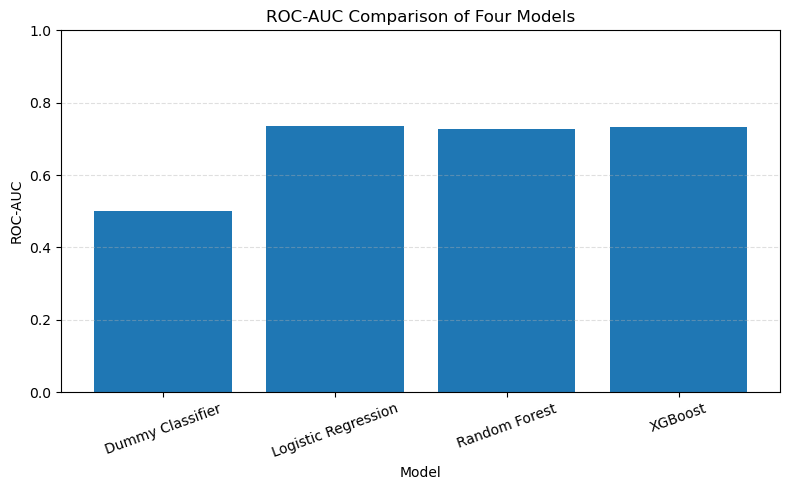

In [39]:
import matplotlib.pyplot as plt

# Plot ROC-AUC comparison
plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["ROC-AUC"]
)

plt.title("ROC-AUC Comparison of Four Models")
plt.xlabel("Model")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


The ROC-AUC chart compares the ability of the four models to distinguish between applicants with and without payment difficulties. 

Logistic Regression achieved the highest ROC-AUC (0.7365), followed by XGBoost (0.7331) and Random Forest (0.7280). The Dummy Classifier achieved 0.5000, representing the baseline performance. These results show that all three machine-learning models performed better than the baseline in distinguishing between the two classes.

## 10. Fairness comparison across four models

This checks error rates by gender and age group. It is an exploratory analysis, not proof that a model is fair or unfair. Sensitive attributes are used for auditing, not as model inputs.




In [40]:
# Prepare demographic information for fairness auditing
demographics = pd.DataFrame(index=X_val.index)

if "CODE_GENDER" in df.columns:
    demographics["gender"] = df.loc[X_val.index, "CODE_GENDER"]

if "DAYS_BIRTH" in df.columns:
    age = -df.loc[X_val.index, "DAYS_BIRTH"] / 365.25

    demographics["age_group"] = pd.cut(
        age,
        bins=[0, 25, 35, 45, 55, 65, 120],
        labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
        right=False
    )


# Calculate false positive and false negative rates

def error_rates(group):
    actual = group["actual"].to_numpy()
    predicted = group["predicted"].to_numpy()

    fp = ((actual == 0) & (predicted == 1)).sum()
    fn = ((actual == 1) & (predicted == 0)).sum()
    tn = ((actual == 0) & (predicted == 0)).sum()
    tp = ((actual == 1) & (predicted == 1)).sum()

    return pd.Series({
        "group size": len(group),
        "false positive rate": fp / (fp + tn) if fp + tn else np.nan,
        "false negative rate": fn / (fn + tp) if fn + tp else np.nan
    })


# Evaluate fairness for all four models

fairness_results = []

for name, pipeline in trained_models.items():

    probability = pipeline.predict_proba(X_val)[:, 1]
    prediction = (probability >= 0.5).astype(int)

    audit = demographics.copy()
    audit["actual"] = y_val
    audit["predicted"] = prediction

    for column in ["gender", "age_group"]:

        if column in audit.columns:

            group_results = (
                audit.groupby(column, observed=False)
                .apply(
                    error_rates,
                    include_groups=False
                )
                .reset_index()
            )

            group_results.insert(0, "Model", name)
            group_results.insert(1, "Group type", column)

            fairness_results.append(group_results)


# Combine and display results

fairness_comparison = pd.concat(
    fairness_results,
    ignore_index=True
)

display(fairness_comparison.round(3))


,Model,Group type,gender,group size,false positive rate,false negative rate,age_group
0,Dummy Classifier,gender,F,40561.0,0.000,1.000,NaN
1,Dummy Classifier,gender,M,20940.0,0.000,1.000,NaN
2,Dummy Classifier,gender,XNA,2.0,0.000,NaN,NaN
3,Dummy Classifier,age_group,NaN,2392.0,0.000,1.000,18-24
4,Dummy Classifier,age_group,NaN,14368.0,0.000,1.000,25-34
5,Dummy Classifier,age_group,NaN,16889.0,0.000,1.000,35-44
6,Dummy Classifier,age_group,NaN,14039.0,0.000,1.000,45-54
7,Dummy Classifier,age_group,NaN,12165.0,0.000,1.000,55-64
8,Dummy Classifier,age_group,NaN,1650.0,0.000,1.000,65+
9,Logistic Regression,gender,F,40561.0,0.000,0.993,NaN


### Interpretation of the results

### 1. Gender comparison
- The Dummy Classifier predicts no positive cases, resulting in a 100% false negative rate for both female and male applicants.
- Logistic Regression has false negative rates of 99.3% for females and 98.9% for males.
- Random Forest has false negative rates of 99.4% for females and 99.3% for males.
- XGBoost has lower false negative rates of 96.6% for females and 95.7% for males.

### 2. Age comparison
- False negative rates are very high across all age groups.
- Logistic Regression and Random Forest generally show increasing false negative rates among older applicants.
- XGBoost has lower false negative rates for most age groups, although its rate reaches 100% for applicants aged 65 and above.

### Overall Findings

The fairness comparison shows differences in prediction error rates across gender and age groups for all four models. Among the three machine-learning models, XGBoost has the lowest false negative rates for most groups, while Logistic Regression and Random Forest show similarly high rates.

The Dummy Classifier has a 100% false negative rate because it does not identify any applicants with payment difficulties. Overall, the high false negative rates indicate that the preliminary models miss many applicants experiencing payment difficulties at the default 0.5 classification threshold.

These findings highlight the importance of examining fairness alongside predictive performance. However, lower error rates do not automatically mean that a model is fair or unfair. This is an exploratory analysis, and `the results should not be treated as the final fairness findings of the thesis.`

## 11. Save the model for comparison results

- Saving the model allows it to be reused later without retraining.

In [41]:
os.makedirs("outputs/preliminary", exist_ok=True)

# Save model comparison results
model_comparison.to_csv(
    "outputs/preliminary/model_comparison.csv",
    index=False
)

# Save fairness comparison results
fairness_comparison.to_csv(
    "outputs/preliminary/fairness_comparison.csv",
    index=False
)

print("Preliminary model and fairness results saved successfully.")


Preliminary model and fairness results saved successfully.


### 11.1 Save the Trained Models

I saved all four trained models so they can be reused later without repeating the training process. This also allows me to keep the initial models available for further analysis and comparison.

In [42]:
import joblib
import os

# Create a folder for preliminary models
os.makedirs("outputs/preliminary/models", exist_ok=True)

# Save all four trained models
for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"

    joblib.dump(
        model,
        f"outputs/preliminary/models/{filename}"
    )

    print(f"{name} saved successfully.")



Dummy Classifier saved successfully.
Logistic Regression saved successfully.
Random Forest saved successfully.
XGBoost saved successfully.


## 12. Next steps (outside this notebook)

The final modelling workflow (preprocessing pipeline, Random Forest and XGBoost, five-fold cross-validation, SHAP, fairness and calibration analysis, MLflow tracking, tests) is in the project pipeline. See the repository README for how to run it.
